<a href="https://colab.research.google.com/github/aatika-hakim/AI-Chatbot/blob/master/AI_Exercise2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# Import necessary libraries
import pandas as pd
import numpy as np

# dataset
df = pd.read_csv('titanic.csv')

print("Dataset Shape (Rows, Columns):")
print(df.shape)

# Display the first 7 rows of the dataset
print("\nFirst 7 rows of the dataset:")
display(df.head(7))

Dataset Shape (Rows, Columns):
(714, 8)

First 7 rows of the dataset:


,survived,pclass,name,sex,age,fare,sibsp,parch
0,0,3,"Braund, Mr. Owen Harris",male,22.0,7.2500,1,0
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,71.2833,1,0
2,1,3,"Heikkinen, Miss. Laina",female,26.0,7.9250,0,0
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,53.1000,1,0
4,0,3,"Allen, Mr. William Henry",male,35.0,8.0500,0,0
5,0,1,"McCarthy, Mr. Timothy J",male,54.0,51.8625,0,0
6,0,3,"Palsson, Master. Gosta Leonard",male,2.0,21.0750,3,1


In [25]:
# Descriptive statistics for numerical variables
print("Descriptive Statistics for Numerical Variables:")
display(df.describe())


print("\nNumerical Variables:")
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(numerical_cols)

print("\nCategorical Variables:")
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(categorical_cols)

print("\nFrequency Distribution for 'Sex':")
print(df['sex'].value_counts())


pclass_col = 'pclass' if 'pclass' in df.columns else 'Passenger class'
print(f"\nFrequency Distribution for '{pclass_col}':")
print(df[pclass_col].value_counts())

Descriptive Statistics for Numerical Variables:


,survived,pclass,age,fare,sibsp,parch
count,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000
mean,0.406162,2.236695,29.699118,34.694514,0.512605,0.431373
std,0.491460,0.838250,14.526497,52.918930,0.929783,0.853289
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,20.125000,8.050000,0.000000,0.000000
50%,0.000000,2.000000,28.000000,15.741700,0.000000,0.000000
75%,1.000000,3.000000,38.000000,33.375000,1.000000,1.000000
max,1.000000,3.000000,80.000000,512.329200,5.000000,6.000000



Numerical Variables:
['survived', 'pclass', 'age', 'fare', 'sibsp', 'parch']

Categorical Variables:
['name', 'sex']

Frequency Distribution for 'Sex':
sex
male      453
female    261
Name: count, dtype: int64

Frequency Distribution for 'pclass':
pclass
3    355
1    186
2    173
Name: count, dtype: int64


In [6]:
# Count missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values
for col in df.select_dtypes(include=['int64', 'float64']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
survived    0
pclass      0
name        0
sex         0
age         0
fare        0
sibsp       0
parch       0
dtype: int64

Missing values after cleaning:
survived    0
pclass      0
name        0
sex         0
age         0
fare        0
sibsp       0
parch       0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

# Preprocess categorical features
df_model = df.copy()
if 'Sex' in df_model.columns:
    df_model['Sex'] = LabelEncoder().fit_transform(df_model['Sex'])

drop_cols = ['Name', 'Ticket', 'Cabin', 'PassengerId']
df_model = df_model.drop(columns=[col for col in drop_cols if col in df_model.columns])

# Handle any remaining categorical columns
for col in df_model.select_dtypes(include=['object']).columns:
    df_model[col] = LabelEncoder().fit_transform(df_model[col].astype(str))

# Identify Target (dependent) variable ('Survived') and independent features
X = df_model.drop(columns=['survived'])
y = df_model['survived']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build and train the SVC model
svc_model = SVC(kernel='linear', random_state=42)
svc_model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = svc_model.predict(X_test)

# Evaluate the model
print("Model Evaluation Metrics:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Evaluation Metrics:
Accuracy:  0.7343
Precision: 0.6667
Recall:    0.6429
F1-Score:  0.6545

Confusion Matrix:
[[69 18]
 [20 36]]


/tmp/ipykernel_2956/3586400548.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='pclass', y='survived', hue='sex', data=df, ci=None)


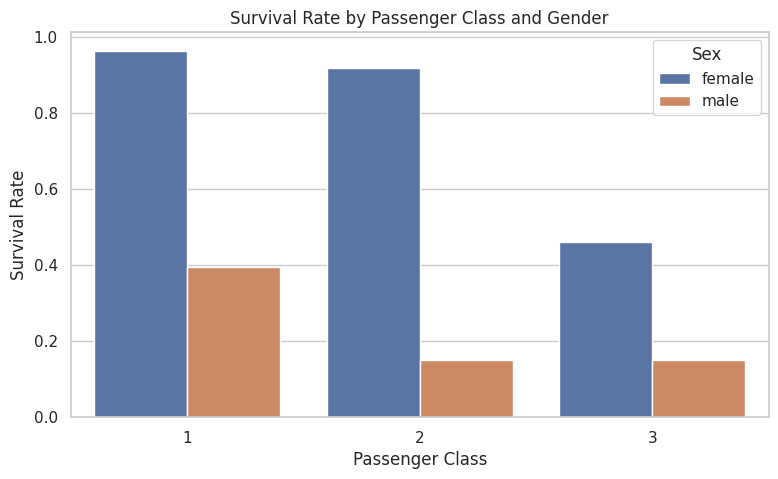

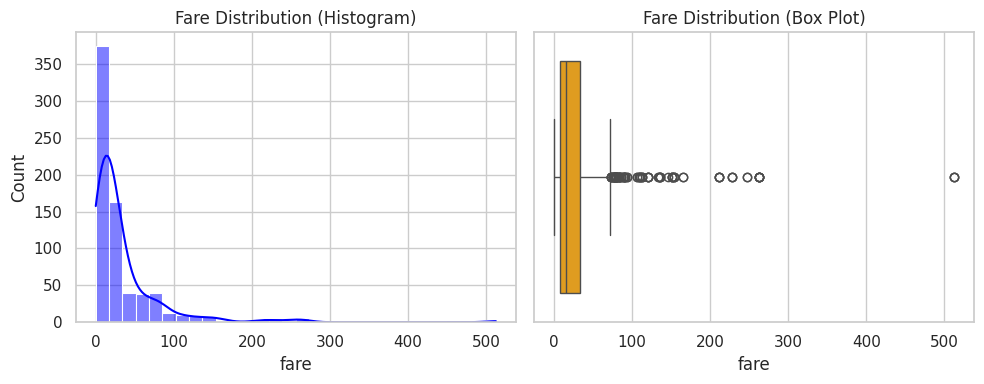

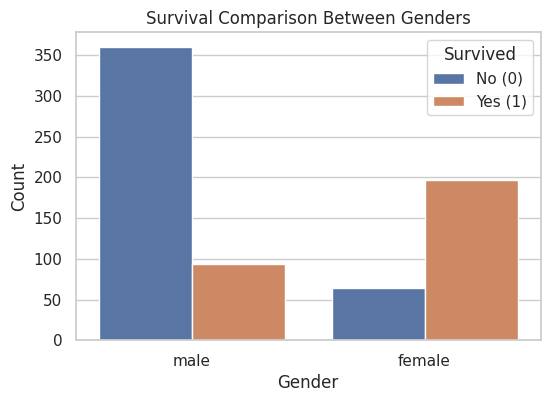

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set(style="whitegrid")

# 1. Combined relationship between Gender, Passenger Class, and Survival
plt.figure(figsize=(9, 5))
sns.barplot(x='pclass', y='survived', hue='sex', data=df, ci=None)
plt.title('Survival Rate by Passenger Class and Gender')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.legend(title='Sex')
plt.show()

# 2. Distribution of passenger Fare
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['fare'], kde=True, bins=30, color='blue')
plt.title('Fare Distribution (Histogram)')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['fare'], color='orange')
plt.title('Fare Distribution (Box Plot)')
plt.tight_layout()
plt.show()

# 3. Compare survival and non-survival among male and female passengers
plt.figure(figsize=(6, 4))
sns.countplot(x='sex', hue='survived', data=df)
plt.title('Survival Comparison Between Genders')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Survived', labels=['No (0)', 'Yes (1)'])
plt.show()